In [1]:
import numpy as np
import pandas as pd
from scipy.spatial import ConvexHull, Voronoi, distance, voronoi_plot_2d
from shapely.geometry import Polygon, Point
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, pairwise_distances
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import time

class ECKMeans:
    def __init__(self, X, k=8):
        self.X             = np.array(X)
        self.k             = k if k is not None else 8
        self.labels_       = None
        self.centroids_    = None
        self.membership_   = None
        self.init_centers_ = None
        self.n_iter_       = None
        self.best_m_       = None

    def _compute_convex_hull(self):
        return ConvexHull(self.X)

    def _compute_voronoi(self):
        return Voronoi(self.X)

    def _get_voronoi_vertices(self, vor):
        return vor.vertices

    def _in_hull(self, vor_v, hull):
        hull_points = hull.points[hull.vertices]
        if not np.array_equal(hull_points[0], hull_points[-1]):
            hull_points = np.append(hull_points, [hull_points[0]], axis=0)
        hull_polygon = Polygon(hull_points)
        valid_vertices = []
        for v in vor_v:
            if hull_polygon.contains(Point(v)):
                valid_vertices.append(v)
        return np.array(valid_vertices)

    def _circle_vor_in(self, vor_in):
        circles = []
        if len(vor_in) == 0:
            return circles
        dists     = distance.cdist(vor_in, self.X)
        min_dists = np.min(dists, axis=1)
        for i, center in enumerate(vor_in):
            circles.append((center, min_dists[i]))
        return circles

    def _sort_circle(self, circles):
        return sorted(circles, key=lambda x: x[1], reverse=True)

    def _sort_circum(self, sorted_circles, tol=1e-6):
        circum_points = []
        for center, r in sorted_circles:
            d   = distance.cdist([center], self.X)[0]
            pts = self.X[np.abs(d - r) < tol]
            if len(pts) > 0:
                # CHANGED: instead of taking every circumference point of a
                # circle (which let big circles hog all k slots and left
                # some circles with zero representatives), pick exactly ONE
                # random point per circle. This guarantees every circle
                # (every green empty circle in the figure) contributes
                # exactly one initial center.
                chosen_idx = np.random.choice(len(pts))
                circum_points.append(tuple(pts[chosen_idx]))
        return circum_points

    def _final_circum(self, circum_points):
        return np.array(list(dict.fromkeys(circum_points)))

    def _run_fcm(self, init_centers, m, max_iter, tol):
        n       = self.X.shape[0]
        centers = np.copy(init_centers)

        n_iter = max_iter

        # ── 1. PRINT INITIAL CENTERS ──────────────────────────────────────
        print("\n" + "=" * 60)
        print(f"{'Initial Centers (from Geometry)':^60}")
        print("=" * 60)
        for j in range(self.k):
            # Rounds the coordinates to 4 decimal places for clean reading
            print(f"  C{j+1} = {np.round(centers[j], 4)}")
        print("=" * 60)

        # ── Distance Calculation ──────────────────────────────────────────
        def calc_distances(X, centers):
            D = np.zeros((n, self.k))
            for i in range(n):
                for j in range(self.k):
                    D[i, j] = np.linalg.norm(X[i] - centers[j])
            return D

        # ── Standard FCM Membership ───────────────────────────────────────
        def calc_membership(D, m):
            U = np.zeros((n, self.k))
            for i in range(n):
                inv_powered = (1.0 / np.maximum(D[i], 1e-10)) ** m
                U[i]        = inv_powered / np.sum(inv_powered)
            return U

        # ── Update cluster centers ────────────────────────────────────────
        def update_centers(U, m):
            new_centers = np.zeros((self.k, self.X.shape[1]))
            for j in range(self.k):
                weights        = U[:, j] ** m
                new_centers[j] = (np.sum(weights[:, None] * self.X, axis=0)
                                  / np.sum(weights))
            return new_centers

        # ── DISTANCES & INITIALIZATION ────────────────────────────────────
        D = calc_distances(self.X, centers)

        # FIX: We must create a blank U here so the loop has something to copy on iteration 0
        U = np.zeros((n, self.k))

        # ── YOUR PROPOSED LOOP ORDER ──────────────────────────────────────
        for iteration in range(max_iter):
            U_old = U.copy()

            # 1. Calculate Standard Membership FIRST
            U = calc_membership(D, m)

            # 2. Update centers using the new Standard U
            centers = update_centers(U, m)

            # 3. Recalculate distances to the newly moved centers
            D = calc_distances(self.X, centers)

            # 4. Convergence check
            if np.linalg.norm(U - U_old) < tol:
                n_iter = iteration + 1
                break

        return centers, U, n_iter

    def fit(self):
        # Seed for reproducibility: makes the random point chosen per
        # circle in _sort_circum (and any random fallback below) the
        # same across repeated runs.
        #np.random.seed(0)
        # ─────────────────────────────────────────────
        hull              = self._compute_convex_hull()
        vor               = self._compute_voronoi()
        vor_v             = self._get_voronoi_vertices(vor)
        vor_in            = self._in_hull(vor_v, hull)
        circles           = self._circle_vor_in(vor_in)
        sorted_circles    = self._sort_circle(circles)
        circum_candidates = self._sort_circum(sorted_circles)
        unique_candidates = self._final_circum(circum_candidates)

        if len(unique_candidates) >= self.k:
            init_centers = unique_candidates[:self.k]
        elif len(unique_candidates) > 0:
            needed         = self.k - len(unique_candidates)
            np.random.seed(0)
            random_indices = np.random.choice(len(self.X), needed, replace=False)
            random_points  = self.X[random_indices]
            init_centers   = np.vstack((unique_candidates, random_points))
        else:
            np.random.seed(0)
            init_centers   = self.X[np.random.choice(len(self.X), self.k, replace=False)]

        self.init_centers_ = init_centers 

        # ── FCM hyper-parameter search ────────────────────────────────────
        tol             = 1e-5
        m_values        = [1.5, 2.0, 2.5, 3.0]
        max_iter_values = [500]

        best_centers  = None
        best_U        = None
        best_n_iter   = float('inf')
        best_m        = None
        best_max_iter = None

        print("\n" + "-" * 45)
        print("Starting FCM Hyper-parameter Search (Proposed Order)...")
        for m in m_values:
            for max_iter in max_iter_values:
                centers, U, n_iter = self._run_fcm(
                    self.init_centers_, m, max_iter, tol
                )
                print(f"  m={m}  max_iter={max_iter}  converged_at={n_iter}")

                if n_iter < best_n_iter:
                    best_centers  = centers
                    best_U        = U
                    best_n_iter   = n_iter
                    best_m        = m
                    best_max_iter = max_iter

        print(f"\n  Best Result → m={best_m}  max_iter={best_max_iter}  n_iter={best_n_iter}")
        print("-" * 45)

        self.centroids_  = best_centers
        self.membership_ = best_U
        self.labels_     = np.argmax(best_U, axis=1)
        self.n_iter_     = best_n_iter
        self.best_m_     = best_m

        return self


def run_standard_fcm(X, n_clusters, m=2.0, max_iter=500, tol=1e-5):
    """
    Runs the complete Standard Fuzzy C-Means loop until convergence.
    All helper functions are encapsulated inside to keep the namespace clean.
    """

    # --- 1. Encapsulated Helper Functions ---
    def initialize_membership(n_samples, n_clusters):
        """Randomly initializes the membership matrix U."""
        return np.random.dirichlet(np.ones(n_clusters), size=n_samples)

    def compute_centers(X, U, m):
        """Calculates the new cluster centers based on current memberships."""
        Um = U ** m
        centers = np.zeros((n_clusters, X.shape[1]))
        for j in range(n_clusters):
            numerator = np.sum((Um[:, j][:, np.newaxis]) * X, axis=0)
            denominator = np.sum(Um[:, j])
            centers[j] = numerator / (denominator + 1e-10) 
        return centers

    def compute_membership(X, centers, m):
        """Updates the membership matrix U based on distance to new centers."""
        n_samples = X.shape[0]
        U = np.zeros((n_samples, n_clusters))
        for i in range(n_samples):
            distances = [np.linalg.norm(X[i] - centers[k]) for k in range(n_clusters)]
            for j in range(n_clusters):
                if distances[j] == 0:
                    U[i] = 0
                    U[i, j] = 1
                    break
                else:
                    total = sum((distances[j] / (distances[k] + 1e-10)) ** (2 / (m - 1)) 
                                for k in range(n_clusters))
                    U[i, j] = 1 / total
        return U

    # --- 2. Main Execution Loop ---
    U = initialize_membership(X.shape[0], n_clusters)
    conv_at = max_iter
    centers = None

    for it in range(max_iter):
        U_old = U.copy()
        centers = compute_centers(X, U, m)
        U = compute_membership(X, centers, m)

        # Convergence check
        if np.max(np.abs(U - U_old)) < tol:
            conv_at = it + 1
            break

    return centers, U, conv_at

In [2]:
"""
FCM-WOA: Fuzzy C-Means combined with Whale Optimization Algorithm
Based on: Hashemi, S.E., Gholian-Jouybari, F., Hajiaghaei-Keshteli, M. (2023)

CORRECTED VERSION:
  - During the WOA phase, only U is updated. Centers are held FIXED for
    the whole WOA phase, matching the paper. Fitness is evaluated
    against pre-computed fixed distances instead of silently
    recomputing an FCM-optimal center every iteration.
  - Centers are (re)computed via Eq. (12) only once, right after the
    WOA phase ends, then alternated with U in the FCM phase.
  - FCM-phase convergence now tracks the global best objective each
    iteration instead of one index's center shift going stale.
"""

def compute_distances(X, V):
    D = np.sum((X[:, None, :] - V[None, :, :]) ** 2, axis=2)
    return np.maximum(D, 1e-10)

def update_membership(D, m):
    power = 1.0 / (m - 1.0)
    ratio = (D[:, :, None] / (D[:, None, :] + 1e-10)) ** power
    U = 1.0 / np.sum(ratio, axis=2)
    return U

def update_centers(X, U, m):
    Um = U ** m
    V = (Um.T @ X) / (Um.sum(axis=0)[:, None] + 1e-10)
    return V

def fcm_objective(D, U, m):
    Um = U ** m
    return np.sum(Um * D)

def initialize_population(X, c, n_pop, m):
    d = X.shape[1]
    V_min = np.min(X, axis=0)
    V_max = np.max(X, axis=0)
    V_pop, U_pop = [], []
    for l in range(n_pop):
        V_l = V_min + np.random.rand(c, d) * (V_max - V_min)
        D_l = compute_distances(X, V_l)
        U_l = update_membership(D_l, m)
        V_pop.append(V_l)
        U_pop.append(U_l)
    return V_pop, U_pop

def woa_update_population(X, U_pop, U_best, m, a):
    n_pop = len(U_pop)
    b = 1.0
    new_U_pop = []
    for l in range(n_pop):
        U_l = U_pop[l]
        n, c = U_l.shape
        r = np.random.rand(n, c)
        p = np.random.rand()
        L = np.random.uniform(-1.0, 1.0, size=(n, c))
        A = 2.0 * a * r - a
        Dd = np.abs(U_best - U_l)
        branch_1 = U_best - A * Dd
        branch_2 = Dd * np.exp(b * L) * np.cos(2.0 * np.pi * L) + U_best
        U_new = branch_1 if p < 0.5 else branch_2
        U_new = np.clip(U_new, 0.0, 1.0)
        row_sums = np.maximum(np.sum(U_new, axis=1, keepdims=True), 1e-12)

        U_new = U_new / row_sums
        new_U_pop.append(U_new)
    return new_U_pop

def fcm_woa(X, c, m=2.0, n_pop=50,
            woa_max_iter=40, fcm_max_iter=20,
            total_max_iter=150, stall_limit=3,
            eps=1e-5, verbose=True):
    V_pop, U_pop = initialize_population(X, c, n_pop, m)

    def eval_with_recomputed_centers(U_pop):
        """Init + FCM phase: centers are genuinely meant to be recomputed."""
        best_J = np.inf
        best_idx = -1
        best_V = None
        for l in range(len(U_pop)):
            V_l = update_centers(X, U_pop[l], m)
            D_l = compute_distances(X, V_l)
            J_l = fcm_objective(D_l, U_pop[l], m)
            if J_l < best_J:
                best_J, best_idx, best_V = J_l, l, V_l
        return best_idx, best_J, best_V

    def eval_with_fixed_distances(U_pop, D_pop):
        """WOA phase: centers/distances stay fixed while only U evolves."""
        best_J = np.inf
        best_idx = -1
        for l in range(len(U_pop)):
            J_l = fcm_objective(D_pop[l], U_pop[l], m)
            if J_l < best_J:
                best_J, best_idx = J_l, l
        return best_idx, best_J

    best_idx, best_J, V_best = eval_with_recomputed_centers(U_pop)
    U_best = U_pop[best_idx].copy()

    stall_count = 0
    outer_iter = 0

    while outer_iter < total_max_iter and stall_count < stall_limit:
        outer_iter += 1
        prev_best_J = best_J

        # ---- WOA phase: U evolves, centers/distances FIXED ----
        D_pop = [compute_distances(X, V_pop[l]) for l in range(n_pop)]

        woa_iter = 0
        woa_stall_count = 0
        woa_prev_best_J = best_J
        while woa_iter < woa_max_iter and woa_stall_count < stall_limit:
            woa_iter += 1
            a = 2.0 - woa_iter * (2.0 / woa_max_iter)
            U_pop = woa_update_population(X, U_pop, U_best, m, a)

            idx, J_val = eval_with_fixed_distances(U_pop, D_pop)
            if J_val < best_J:
                best_J, best_idx = J_val, idx
                U_best = U_pop[best_idx].copy()

            if (woa_prev_best_J - best_J) > eps:
                woa_stall_count = 0
            else:
                woa_stall_count += 1
            woa_prev_best_J = best_J

        # ---- Centers computed ONLY now, after WOA phase ends (Eq. 12) ----
        for l in range(n_pop):
            V_pop[l] = update_centers(X, U_pop[l], m)
        V_best = V_pop[best_idx].copy()

        # ---- FCM phase: alternate U (Eq. 9) / V (Eq. 12) ----
        fcm_iter = 0
        #fcm_prev_best_J = best_J
        while fcm_iter < fcm_max_iter:
            fcm_iter += 1
            max_center_shift = 0.0
            for l in range(n_pop):
                V_before = V_pop[l].copy()
                D_l = compute_distances(X, V_pop[l])
                U_pop[l] = update_membership(D_l, m)
                V_pop[l] = update_centers(X, U_pop[l], m)

                shift = np.max(np.abs(V_pop[l] - V_before))
                if shift > max_center_shift:
                    max_center_shift = shift

            idx, J_val, V_val = eval_with_recomputed_centers(U_pop)
            if J_val < best_J:
                best_J, best_idx = J_val, idx
                U_best = U_pop[best_idx].copy()
                V_best = V_val

            if max_center_shift < eps:
                break

            '''fcm_improvement = fcm_prev_best_J - best_J
            fcm_prev_best_J = best_J
            if fcm_improvement < eps:
                break'''

        if (prev_best_J - best_J) > eps:
            stall_count = 0
        else:
            stall_count += 1

        if verbose:
            print("Outer iter", outer_iter, "  best J =", round(best_J, 6),
                  "  stall_count =", stall_count)

    return {"V": V_best, "U": U_best, "J": best_J, "outer_iterations": outer_iter}


def fcm_woa_big_data(X, c, n_batches, m=2.0, n_pop=50,
                      woa_max_iter=40, fcm_max_iter=20,
                      total_max_iter=150, verbose=True):
    """Algorithm 2: Big Data Extension (Batched FCM-WOA)"""
    n = X.shape[0]
    indices = np.random.permutation(n)
    batches = np.array_split(indices, n_batches)

    batch_centers = []
    for b in range(n_batches):
        X_batch = X[batches[b]]
        if verbose:
            print(f"Processing batch {b + 1} of {n_batches} ({X_batch.shape[0]} points)")
        result = fcm_woa(X_batch, c, m=m, n_pop=n_pop,
                          woa_max_iter=woa_max_iter, fcm_max_iter=fcm_max_iter,
                          total_max_iter=total_max_iter, verbose=False)
        batch_centers.append(result["V"])

    all_centers = np.vstack(batch_centers)
    if verbose:
        print(f"Combining {all_centers.shape[0]} batch centers with FCM-WOA ...")

    combine_result = fcm_woa(all_centers, c, m=m, n_pop=n_pop,
                              woa_max_iter=woa_max_iter, fcm_max_iter=fcm_max_iter,
                              total_max_iter=total_max_iter, verbose=False)
    V_final = combine_result["V"]
    D_final = compute_distances(X, V_final)
    U_final = update_membership(D_final, m)
    J_final = fcm_objective(D_final, U_final, m)

    return {"V": V_final, "U": U_final, "J": J_final,
            "outer_iterations": combine_result["outer_iterations"]}

def hard_labels_from_U(U):
    return np.argmax(U, axis=1)

X_raw Shape (High Dimensional): (1484, 8)
Number of clusters dynamically set to: 10

---------------------------------------------
Starting FCM Hyper-parameter Search (Proposed Order)...

              Initial Centers (from Geometry)               
  C1 = [-0.0495  0.6485]
  C2 = [-0.1869  0.2535]
  C3 = [-0.0855  0.2974]
  C4 = [0.4973 0.3441]
  C5 = [-0.043   0.3196]
  C6 = [0.0613 0.5081]
  C7 = [0.3618 0.2776]
  C8 = [-0.4044  0.2687]
  C9 = [0.3822 0.1839]
  C10 = [0.2106 0.506 ]
  m=1.5  max_iter=500  converged_at=500

              Initial Centers (from Geometry)               
  C1 = [-0.0495  0.6485]
  C2 = [-0.1869  0.2535]
  C3 = [-0.0855  0.2974]
  C4 = [0.4973 0.3441]
  C5 = [-0.043   0.3196]
  C6 = [0.0613 0.5081]
  C7 = [0.3618 0.2776]
  C8 = [-0.4044  0.2687]
  C9 = [0.3822 0.1839]
  C10 = [0.2106 0.506 ]
  m=2.0  max_iter=500  converged_at=396

              Initial Centers (from Geometry)               
  C1 = [-0.0495  0.6485]
  C2 = [-0.1869  0.2535]
  C3 = [-0.0855

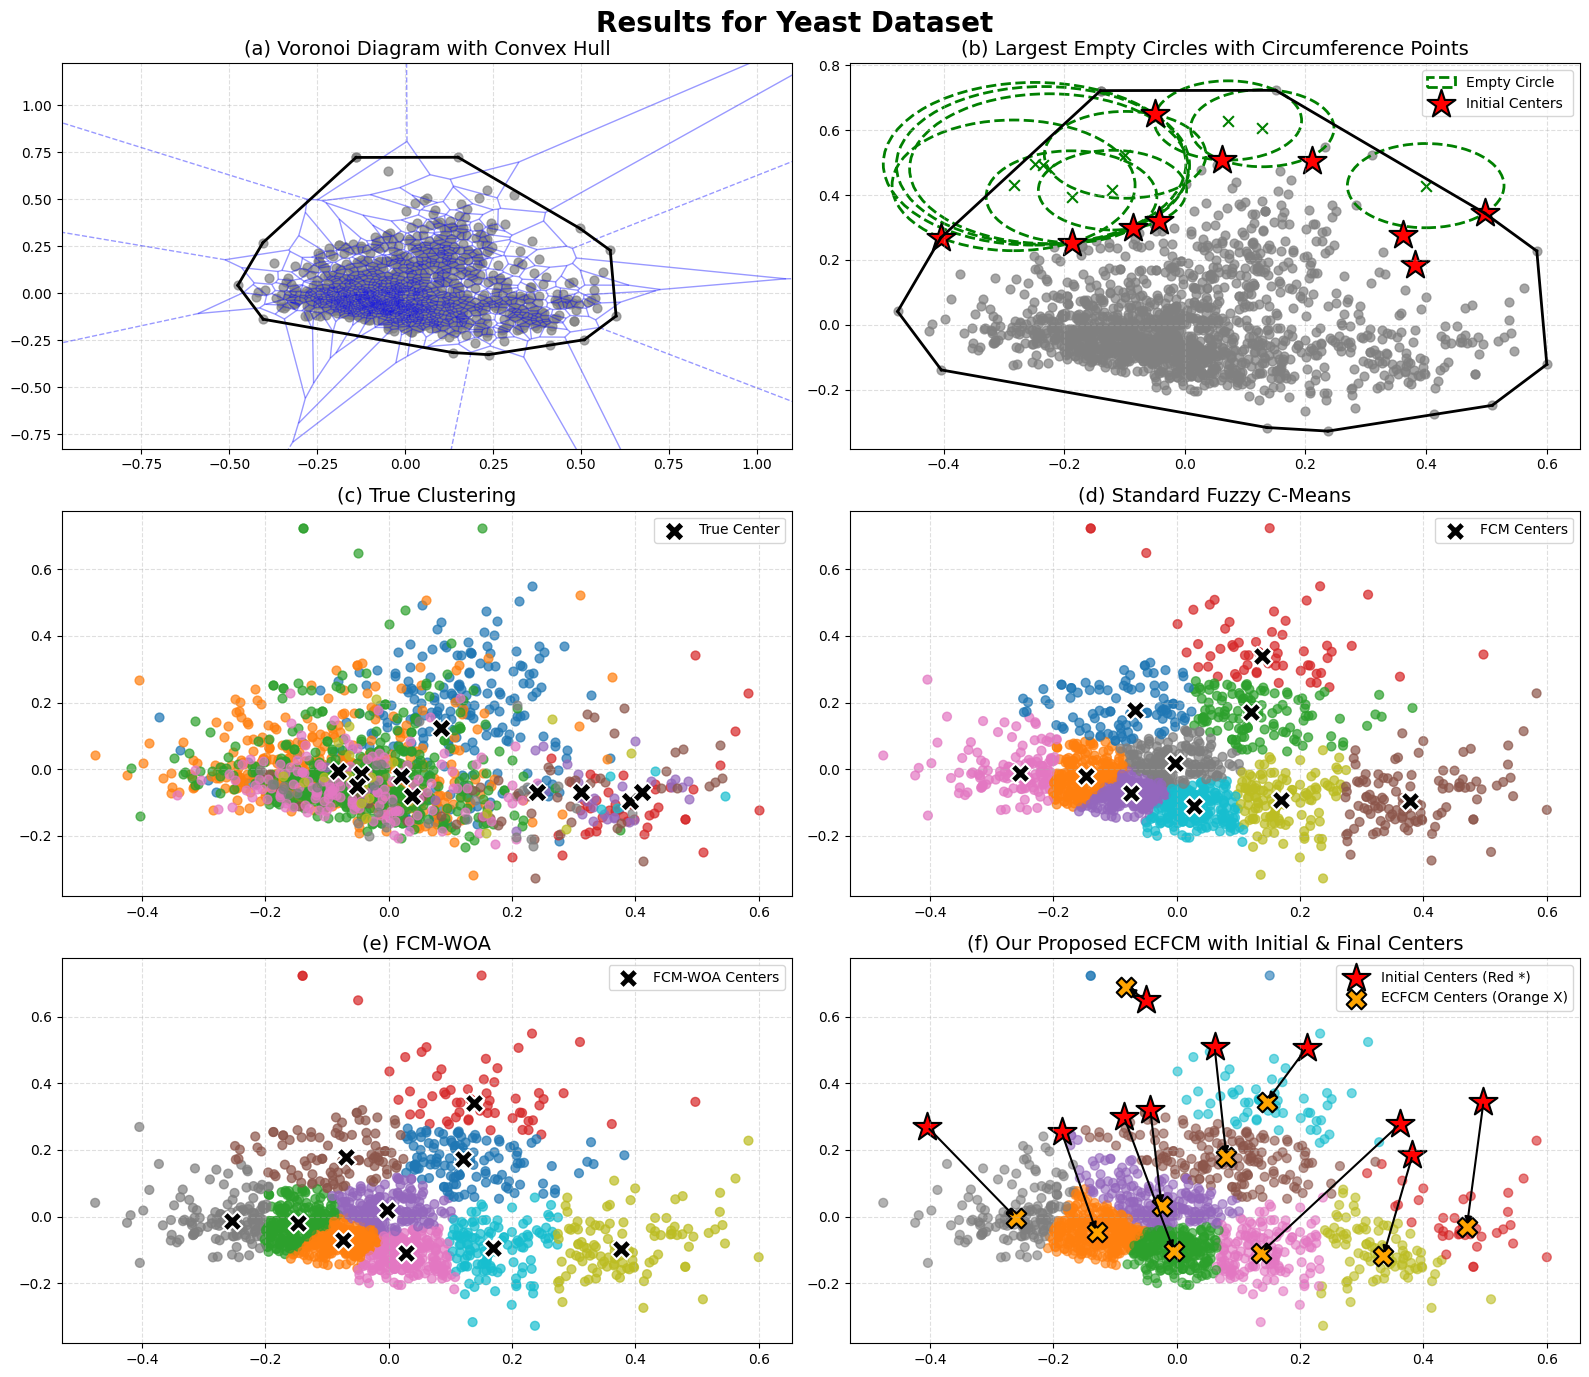

In [ ]:
# 1. Load data
filepath = r"./Real Datasets/Yeast.csv"
df = pd.read_csv(filepath)
#df = pd.read_csv("./datafiles/spiral.txt", sep="\t", header=None, names=["A", "B", "Class"])
#df = pd.read_csv("./datafiles/breast.txt", sep=" ", header=None, names=["A", "B", "C", "D", "E", "F", "G", "H", "Class"])

# 2. Extract Labels safely BEFORE dropping them
if 'Class' in df.columns:
    y_true_raw = df['Class']
    df = df.drop('Class', axis=1)
else:
    # Fallback if 'Class' header isn't found
    y_true_raw = df.iloc[:, -1]
    df = df.iloc[:, :-1]

X_raw = df.select_dtypes(include=[np.number]).values
print(f"X_raw Shape (High Dimensional): {X_raw.shape}")


# 3. Reduce to 2D using PCA
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_raw)
# print(X_2d)

# 4.1. 
# RUN STANDARD FCM (So Panel E has data to plot!)
# Assuming your fuzzy_cmeans function is loaded in memory from Cell 1
# n_clusters = 28
n_clusters = len(np.unique(y_true_raw)) 
print(f"Number of clusters dynamically set to: {n_clusters}")
start_std = time.time()
centers_std, U_std, IT_std = run_standard_fcm(X_2d, n_clusters=n_clusters, m=2.0)
labels_std = np.argmax(U_std, axis=1)
elapsed_std = time.time() - start_std

# 4. Fit the model (adjust k to however many clusters are in Atom.csv)
start_time = time.time()
ec_fcm = ECKMeans(X=X_2d, k=n_clusters)  # Assuming Atom has 2 classes based on standard Atom datasets, change if needed
ec_fcm.fit()
end_time = time.time()
total_time = end_time - start_time

# Print final cluster centers for Eckmeans
print("\n")
print("-" * 50)
print(f"{'Final Cluster Centers':^50}")
print("-" * 50)
print(f"{'Cluster':<10} | {'Center Coordinates':>20}")
print("-" * 50)
for j in range(ec_fcm.k):
    center_coords = np.round(ec_fcm.centroids_[j], 4)
    print(f"{'Cluster '+str(j+1):<10} | {str(center_coords):>20}")
print("-" * 50)

# 5. Reconstruct geometry for plotting
hull              = ec_fcm._compute_convex_hull()
vor               = ec_fcm._compute_voronoi()
vor_v             = ec_fcm._get_voronoi_vertices(vor)
vor_in            = ec_fcm._in_hull(vor_v, hull)
circles           = ec_fcm._circle_vor_in(vor_in)
sorted_circles    = ec_fcm._sort_circle(circles)
top_k_circles     = sorted_circles[:ec_fcm.k]
circum_candidates = ec_fcm._sort_circum(top_k_circles)
#circum_candidates = ec_fcm._sort_circum(sorted_circles)
unique_candidates = ec_fcm._final_circum(circum_candidates)

# ─────────────────────────────────────────────────────────────────
# Run FCM-WOA (merged from fcm_woa_without_morma.ipynb) so panel (e)
# below -- the blank axs[2, 0] slot -- has data to plot
# Auto-switches to the Big Data batched extension for large datasets,
# same as fcm_woa_without_morma.ipynb Cell 6 & 8
# ─────────────────────────────────────────────────────────────────
start = time.time()
DATA_THRESHOLD = 5000  # If rows > threshold, trigger Big Data algorithm

if X_2d.shape[0] >= DATA_THRESHOLD:
    print(f"\n[INFO] Dataset has {X_2d.shape[0]} rows (>{DATA_THRESHOLD}).")
    print("[INFO] Automatically switching to Big Data Extension (Algorithm 2)!")

    n_batches_woa = max(2, X_2d.shape[0] // 1000)
    algo_name_woa = "fcm_woa_big_data"

    result_woa = fcm_woa_big_data(
        X_2d, n_clusters, n_batches=n_batches_woa, m=2.0,
        n_pop=50,
        woa_max_iter=40,
        fcm_max_iter=20,
        total_max_iter=150,
        verbose=False
    )
else:
    print(f"\n[INFO] Dataset has {X_2d.shape[0]} rows (<= {DATA_THRESHOLD}).")
    print("[INFO] Using standard FCM-WOA (Algorithm 1).")
    algo_name_woa = "fcm_woa"

    result_woa = fcm_woa(
        X_2d, n_clusters, m=2.0,
        n_pop=50,
        woa_max_iter=40,
        fcm_max_iter=20,
        total_max_iter=150,
        stall_limit=3,
        verbose=False
    )
elapsed = time.time() - start

centers_woa = result_woa["V"]
labels_fcm_woa = hard_labels_from_U(result_woa["U"])

# 6. Plot 4 panels
fig, axs = plt.subplots(3, 2, figsize=(16, 14))
# fig.suptitle('Results of our proposed modified FCM on Glass Dataset', fontsize=20, fontweight='bold')
fig.suptitle('Results for Yeast Dataset', fontsize=20, fontweight='bold')

def draw_hull(ax):
    for simplex in hull.simplices:
        ax.plot(X_2d[simplex, 0], X_2d[simplex, 1], 'k-', lw=2)

'''# ---- (a) Convex Hull ----
ax = axs[0, 0]
ax.scatter(X_2d[:, 0], X_2d[:, 1], c='gray', s=40, alpha=0.7, label='Data Points')
draw_hull(ax)
ax.set_title('(a) Convex Hull', fontsize=14)
ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)'''

# ---- (b) Voronoi Diagram ----
# ax = axs[0, 1]
ax = axs[0, 0]
voronoi_plot_2d(vor, ax=ax, show_points=False, show_vertices=False,
                line_colors='blue', line_alpha=0.4)
ax.scatter(X_2d[:, 0], X_2d[:, 1], c='gray', s=40, alpha=0.7)
draw_hull(ax)
ax.set_xlim(X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5)
ax.set_ylim(X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5)
ax.set_title('(a) Voronoi Diagram with Convex Hull', fontsize=14)
ax.grid(True, linestyle='--', alpha=0.4)

# ---- (c) Largest Empty Circles ----
ax = axs[0, 1]
ax.scatter(X_2d[:, 0], X_2d[:, 1], c='gray', s=40, alpha=0.7)
draw_hull(ax)

for idx, (center, r) in enumerate(sorted_circles[:ec_fcm.k]):
    circle = plt.Circle(center, r, color='green', fill=False,
                         linestyle='--', lw=2,
                         label='Empty Circle' if idx == 0 else "")
    ax.add_patch(circle)
    ax.scatter(center[0], center[1], c='green', marker='x', s=60)

if len(unique_candidates) > 0:
    ax.scatter(ec_fcm.init_centers_[:, 0], ec_fcm.init_centers_[:, 1],
               c='red', marker='*', s=450,
               edgecolors='black', linewidths=1.5, label='Initial Centers ')

ax.set_title('(b) Largest Empty Circles with Circumference Points', fontsize=14)
ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)

#----------- (d) True Cluster -----------
ax = axs[1, 0]

labels = y_true_raw.unique()
principal_df = pd.DataFrame(X_2d)
principal_df['Class'] = y_true_raw.values

for i in labels:
    df_tmp  = principal_df[principal_df['Class'] == i]
    df_tmp1 = df_tmp.drop('Class', axis=1)
    ax.scatter(df_tmp1[0], df_tmp1[1], s=40, alpha=0.7)

# ── True Cluster Centroids (mean of each true class) ─────────────
for i in labels:
    df_tmp      = principal_df[principal_df['Class'] == i]
    df_tmp1     = df_tmp.drop('Class', axis=1)
    true_center = df_tmp1.values.mean(axis=0)   # mean x and mean y
    ax.scatter(true_center[0], true_center[1],
               c='black', marker='X', s=200,
               edgecolors='white', linewidths=1.2,
               zorder=5,label='True Center' if i == labels[0] else "")

ax.set_title("(c) True Clustering", fontsize=14)
'''ax.set_xlabel("X")
ax.set_ylabel("Y")'''
ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)

#----------------(e) Standard FCM --------------
ax = axs[1, 1]

# Transform the multidimensional centers down to 2D using the PCA from Cell 1
# centers_pca = pca.transform(centers)
centers_pca = centers_std

# Plot the data points (using X_2d from Cell 1)
ax.scatter(X_2d[:, 0], X_2d[:, 1], c=labels_std, cmap='tab10', s=40, alpha=0.7)

# Plot the standard FCM cluster centers
ax.scatter(centers_pca[:, 0], centers_pca[:, 1], color='black', s=200, marker='X', edgecolors='white', linewidths=1.5, zorder=5, label='FCM Centers')

ax.set_title(f"(d) Standard Fuzzy C-Means", fontsize=14)
ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)

# ---- (e) FCM-WOA (merged from fcm_woa_without_morma.ipynb) ----
ax = axs[2, 0]
ax.scatter(X_2d[:, 0], X_2d[:, 1], c=labels_fcm_woa, cmap='tab10', s=40, alpha=0.7)
ax.scatter(centers_woa[:, 0], centers_woa[:, 1], color='black', s=200,
           marker='X', edgecolors='white', linewidths=1.5,
           zorder=5, label='FCM-WOA Centers')
ax.set_title("(e) FCM-WOA", fontsize=14)
ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)

# ---- (f) Initial & Final Centers ----
ax = axs[2, 1]
ax.scatter(X_2d[:, 0], X_2d[:, 1], c=ec_fcm.labels_, cmap='tab10', s=40, alpha=0.6)

if ec_fcm.init_centers_ is not None and ec_fcm.centroids_ is not None:
    for init, final in zip(ec_fcm.init_centers_, ec_fcm.centroids_):
        ax.annotate("", xy=final, xytext=init,
                    arrowprops=dict(arrowstyle="-|>", color='black', lw=1.5))

if ec_fcm.init_centers_ is not None:
    ax.scatter(ec_fcm.init_centers_[:, 0], ec_fcm.init_centers_[:, 1],
               c='red', marker='*', s=450,
               edgecolors='black', linewidths=1.5, label='Initial Centers (Red *)')

if ec_fcm.centroids_ is not None:
    ax.scatter(ec_fcm.centroids_[:, 0], ec_fcm.centroids_[:, 1],
               c='orange', marker='X', s=200,
               edgecolors='black', linewidths=1.5,
               label='ECFCM Centers (Orange X)')


ax.set_title('(f) Our Proposed ECFCM with Initial & Final Centers', fontsize=14)
ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [5]:
# ─────────────────────────────────────────────────────────────────
# Compute & Print All Validity Metrics (Proposed ECKM)
# ─────────────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score, davies_bouldin_score, pairwise_distances
from scipy.spatial.distance import cdist

# ── Fuzzy validity helpers ────────────────────────────────────────

def partition_coefficient(U):
    """PC  Partition Coefficient. Best: High (max = 1)."""
    n = U.shape[0]
    return np.sum(U ** 2) / n

def partition_entropy(U):
    """PE – Partition Entropy. Best: Low (min = 0)."""
    n = U.shape[0]
    U_safe = np.clip(U, 1e-10, 1.0)
    return -np.sum(U_safe * np.log(U_safe)) / n

def xie_beni_index(X, U, centers, m=2.0):
    """XB – Xie-Beni Index. Best: Low."""
    n, k = U.shape
    Um = U ** m
    # Compactness: weighted sum of squared distances
    compactness = 0.0
    for j in range(k):
        diff = X - centers[j]
        compactness += np.sum(Um[:, j] * np.sum(diff ** 2, axis=1))
    # Separation: minimum squared distance between centers
    min_sep = np.inf
    for i in range(k):
        for j in range(i + 1, k):
            d = np.sum((centers[i] - centers[j]) ** 2)
            if d < min_sep:
                min_sep = d
    return compactness / (n * min_sep + 1e-10)

def fukuyama_sugeno_index(X, U, centers, m=2.0):
    """FS – Fukuyama-Sugeno Index. Best: Low (more negative = better)."""
    n, k = U.shape
    Um = U ** m
    grand_mean = np.mean(X, axis=0)
    fs = 0.0
    for j in range(k):
        diff_xc  = X - centers[j]           # compactness term
        diff_cg  = centers[j] - grand_mean  # separation term
        compact  = np.sum(Um[:, j] * np.sum(diff_xc ** 2, axis=1))
        separate = np.sum(Um[:, j]) * np.sum(diff_cg ** 2)
        fs += compact - separate
    return fs

def dunn_index(X, labels):
    """Dunn Index – Separation / Compactness. Best: High."""
    unique_labels = np.unique(labels)
    k = len(unique_labels)
    clusters = [X[labels == c] for c in unique_labels]

    # Intra-cluster diameter (max pairwise distance within cluster)
    intra = []
    for c in clusters:
        if len(c) < 2:
            intra.append(0.0)
        else:
            intra.append(np.max(cdist(c, c)))

    max_intra = max(intra) if max(intra) > 0 else 1e-10

    # Inter-cluster minimum distance
    min_inter = np.inf
    for i in range(k):
        for j in range(i + 1, k):
            d = np.min(cdist(clusters[i], clusters[j]))
            if d < min_inter:
                min_inter = d

    return min_inter / max_intra

# ─────────────────────────────────────────────────────────────────
# Compute & Print All Validity Metrics (Proposed ECKM)
# ─────────────────────────────────────────────────────────────────
U       = ec_fcm.membership_        # fuzzy membership matrix  (n × k)
centers = ec_fcm.centroids_         # final cluster centers (2-D, from ECKMeans)
labels  = ec_fcm.labels_            # hard labels

IT = ec_fcm.n_iter_
PC  = partition_coefficient(U)
PE  = partition_entropy(U)
XB  = xie_beni_index(X_2d, U, centers)
FS  = fukuyama_sugeno_index(X_2d, U, centers)
DI  = dunn_index(X_2d, labels)
SC  = silhouette_score(X_2d, labels)
DB  = davies_bouldin_score(X_2d, labels)
all_euclidean = pairwise_distances(X_2d, ec_fcm.centroids_, metric='euclidean')

ED = np.sum(all_euclidean[np.arange(len(X_2d)), ec_fcm.labels_])

# ── Print table ───────────────────────────────────────────────────
print("-" * 75)

print(f"{'Clustering Validity Metrics – Proposed ECKM':^75}")
print("-" * 75)
print(f"{'Metric':<40} | {'Value':>12} | {'Best':>8}")
print("-" * 75)
print(f"{'IT (Iterations)':<35} | {IT:>10} | {'-':>12} | {'-':>12} | {'-':>10}")
print(f"{'PC   Partition Coefficient':<40} | {PC:>12.4f} | {'High':>8}")
print(f"{'PE   Partition Entropy':<40} | {PE:>12.4f} | {'Low':>8}")
print(f"{'XB   Xie-Beni Index':<40} | {XB:>12.4f} | {'Low':>8}")
print(f"{'FS   Fukuyama-Sugeno Index':<40} | {FS:>12.4f} | {'Low':>8}")
print(f"{'Dunn Index':<40} | {DI:>12.4f} | {'High':>8}")
print(f"{'Silhouette Score':<40} | {SC:>12.4f} | {'High':>8}")
print(f"{'DB   Davies-Bouldin Index':<40} | {DB:>12.4f} | {'Low':>8}")
print(f"{'ED (Euclidean Distance) [Lower better]':<35} | {ED:>10.4f} | {'':>12} | {'':>12} | {'':>10}")
print("-" * 75)
print(f"{'Algorithm Fit Time (seconds)':<40} | {total_time:>11.4f}s | {'':>8}")
print("-" * 75)

membership_table = [] 
for j in range(ec_fcm.k):
    center_coords      = ec_fcm.centroids_[j]
    cluster_points_idx = np.where(ec_fcm.labels_ == j)[0]
    if len(cluster_points_idx) > 0:
        avg_membership = np.mean(ec_fcm.membership_[cluster_points_idx, j])
        percentage     = avg_membership * 100
        print(f"{'Cluster '+str(j+1):<10} | {str(np.round(center_coords, 4)):<25} | {percentage:>9.2f}%")
        membership_table.append(
            {"cluster": j + 1, "center": np.round(center_coords, 4), "membership": np.round(percentage, 2)})
    else:
        print(f"{'Cluster '+str(j+1):<10} | {str(np.round(center_coords, 4)):<25} | {'0.00':>9}%")
print("-" * 60)

# ─────────────────────────────────────────────────────────────────
# Excel conversion - ECKM results
# ─────────────────────────────────────────────────────────────────
#if isinstance(df, str):
'''if isinstance(filepath, str):
    dataset_name = os.path.basename(filepath).split(".")[0]
else:
    dataset_name = "Breast_Cancer"''' 

if isinstance(df, str):
    dataset_name = os.path.basename(df).split(".")[0]
else:
    dataset_name = "Spiral"

performance = {
    "dataset": dataset_name,
    "class": n_clusters,
    "M": 2.0,
    "method": "ec_fcm",          # <-- fixed: was "run_standard_fcm"
    "IT": IT,
    "PC": np.round(PC, 4),
    "PE": np.round(PE, 4),
    "XB": np.round(XB, 4),
    "FS": np.round(FS, 4),
    "DI": np.round(DI, 4),
    "SC": np.round(SC, 4),
    "DB": np.round(DB, 4),
    "ED": np.round(ED, 4),
    "total_time": np.round(total_time, 4),
    "membership": membership_table
}

base_data = {k: v for k, v in performance.items() if k != 'membership'}
flattened_rows = [{**base_data, **entry} for entry in performance['membership']]

df_to_append = pd.DataFrame(flattened_rows)
output_file = "final_dataset10_results.xlsx"    # <-- fixed: same file for all methods

is_exist = os.path.exists(output_file)
if not is_exist:
    df_to_append.to_excel(output_file, index=False, engine='openpyxl')
else:
    existing_df = pd.read_excel(output_file, engine='openpyxl')
    existing_df = existing_df[~((existing_df['dataset'] == dataset_name) & (existing_df['method'] == 'ec_fcm'))]
    combined_df = pd.concat([existing_df, df_to_append], ignore_index=True)
    combined_df.to_excel(output_file, index=False, engine='openpyxl')

df_to_append

---------------------------------------------------------------------------
                Clustering Validity Metrics – Proposed ECKM                
---------------------------------------------------------------------------
Metric                                   |        Value |     Best
---------------------------------------------------------------------------
IT (Iterations)                     |        123 |            - |            - |          -
PC   Partition Coefficient               |       0.5690 |     High
PE   Partition Entropy                   |       0.9560 |      Low
XB   Xie-Beni Index                      |       0.1716 |      Low
FS   Fukuyama-Sugeno Index               |     -32.3930 |      Low
Dunn Index                               |       0.0025 |     High
Silhouette Score                         |       0.3268 |     High
DB   Davies-Bouldin Index                |       0.9251 |      Low
ED (Euclidean Distance) [Lower better] |   103.0953 |              |

,dataset,class,M,method,IT,PC,PE,XB,FS,DI,SC,DB,ED,total_time,cluster,center,membership
0,Spiral,10,2.0,ec_fcm,123,0.569,0.956,0.1716,-32.393,0.0025,0.3268,0.9251,103.0953,332.2578,1,"[-0.0822, 0.6896]",87.65
1,Spiral,10,2.0,ec_fcm,123,0.569,0.956,0.1716,-32.393,0.0025,0.3268,0.9251,103.0953,332.2578,2,"[-0.1301, -0.0473]",71.25
2,Spiral,10,2.0,ec_fcm,123,0.569,0.956,0.1716,-32.393,0.0025,0.3268,0.9251,103.0953,332.2578,3,"[-0.0046, -0.1035]",73.45
3,Spiral,10,2.0,ec_fcm,123,0.569,0.956,0.1716,-32.393,0.0025,0.3268,0.9251,103.0953,332.2578,4,"[0.4703, -0.0309]",74.47
4,Spiral,10,2.0,ec_fcm,123,0.569,0.956,0.1716,-32.393,0.0025,0.3268,0.9251,103.0953,332.2578,5,"[-0.0247, 0.0316]",64.77
5,Spiral,10,2.0,ec_fcm,123,0.569,0.956,0.1716,-32.393,0.0025,0.3268,0.9251,103.0953,332.2578,6,"[0.0804, 0.1788]",61.36
6,Spiral,10,2.0,ec_fcm,123,0.569,0.956,0.1716,-32.393,0.0025,0.3268,0.9251,103.0953,332.2578,7,"[0.1364, -0.1089]",68.02
7,Spiral,10,2.0,ec_fcm,123,0.569,0.956,0.1716,-32.393,0.0025,0.3268,0.9251,103.0953,332.2578,8,"[-0.2604, -0.0051]",71.30
8,Spiral,10,2.0,ec_fcm,123,0.569,0.956,0.1716,-32.393,0.0025,0.3268,0.9251,103.0953,332.2578,9,"[0.3348, -0.1179]",70.60
9,Spiral,10,2.0,ec_fcm,123,0.569,0.956,0.1716,-32.393,0.0025,0.3268,0.9251,103.0953,332.2578,10,"[0.1458, 0.3444]",72.70


In [6]:
# ─────────────────────────────────────────────────────────────────
# Compute & Print All Validity Metrics (Proposed ECKM)
# ─────────────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score, davies_bouldin_score, pairwise_distances
from scipy.spatial.distance import cdist

# ── Fuzzy validity helpers ────────────────────────────────────────

def partition_coefficient(U):
    """PC  Partition Coefficient. Best: High (max = 1)."""
    n = U.shape[0]
    return np.sum(U ** 2) / n

def partition_entropy(U):
    """PE – Partition Entropy. Best: Low (min = 0)."""
    n = U.shape[0]
    U_safe = np.clip(U, 1e-10, 1.0)
    return -np.sum(U_safe * np.log(U_safe)) / n

def xie_beni_index(X, U, centers, m=2.0):
    """XB – Xie-Beni Index. Best: Low."""
    n, k = U.shape
    Um = U ** m
    # Compactness: weighted sum of squared distances
    compactness = 0.0
    for j in range(k):
        diff = X - centers[j]
        compactness += np.sum(Um[:, j] * np.sum(diff ** 2, axis=1))
    # Separation: minimum squared distance between centers
    min_sep = np.inf
    for i in range(k):
        for j in range(i + 1, k):
            d = np.sum((centers[i] - centers[j]) ** 2)
            if d < min_sep:
                min_sep = d
    return compactness / (n * min_sep + 1e-10)

def fukuyama_sugeno_index(X, U, centers, m=2.0):
    """FS – Fukuyama-Sugeno Index. Best: Low (more negative = better)."""
    n, k = U.shape
    Um = U ** m
    grand_mean = np.mean(X, axis=0)
    fs = 0.0
    for j in range(k):
        diff_xc  = X - centers[j]           # compactness term
        diff_cg  = centers[j] - grand_mean  # separation term
        compact  = np.sum(Um[:, j] * np.sum(diff_xc ** 2, axis=1))
        separate = np.sum(Um[:, j]) * np.sum(diff_cg ** 2)
        fs += compact - separate
    return fs

def dunn_index(X, labels):
    """Dunn Index – Separation / Compactness. Best: High."""
    unique_labels = np.unique(labels)
    k = len(unique_labels)
    clusters = [X[labels == c] for c in unique_labels]

    # Intra-cluster diameter (max pairwise distance within cluster)
    intra = []
    for c in clusters:
        if len(c) < 2:
            intra.append(0.0)
        else:
            intra.append(np.max(cdist(c, c)))

    max_intra = max(intra) if max(intra) > 0 else 1e-10

    # Inter-cluster minimum distance
    min_inter = np.inf
    for i in range(k):
        for j in range(i + 1, k):
            d = np.min(cdist(clusters[i], clusters[j]))
            if d < min_inter:
                min_inter = d

    return min_inter / max_intra



# ─────────────────────────────────────────────────────────────────
# Compute & Print All Validity Metrics (Standard FCM)
# ─────────────────────────────────────────────────────────────────
U_std       = U_std          # fuzzy membership matrix  (n × k)  -- from Cell 2
centers_std = centers_std    # final cluster centers (2-D)       -- from Cell 2
labels_std  = labels_std     # hard labels                       -- from Cell 2

IT_std = IT_std                  # IT returned by run_standard_fcm in Cell 2
PC_std  = partition_coefficient(U_std)
PE_std  = partition_entropy(U_std)
XB_std  = xie_beni_index(X_2d, U_std, centers_std)
FS_std  = fukuyama_sugeno_index(X_2d, U_std, centers_std)
DI_std  = dunn_index(X_2d, labels_std)
SC_std  = silhouette_score(X_2d, labels_std)
DB_std  = davies_bouldin_score(X_2d, labels_std)
all_euclidean_std = pairwise_distances(X_2d, centers_std, metric='euclidean')

ED_std = np.sum(all_euclidean_std[np.arange(len(X_2d)), labels_std])

# ── Print table ───────────────────────────────────────────────────
print("-" * 75)
print(f"{'Clustering Validity Metrics – Standard FCM':^75}")
print("-" * 75)
print(f"{'Metric':<40} | {'Value':>12} | {'Best':>8}")
print("-" * 75)
print(f"{'IT (Iterations)':<35} | {IT_std:>10} | {'-':>12} | {'-':>12} | {'-':>10}")
print(f"{'PC   Partition Coefficient':<40} | {PC_std:>12.4f} | {'High':>8}")
print(f"{'PE   Partition Entropy':<40} | {PE_std:>12.4f} | {'Low':>8}")
print(f"{'XB   Xie-Beni Index':<40} | {XB_std:>12.4f} | {'Low':>8}")
print(f"{'FS   Fukuyama-Sugeno Index':<40} | {FS_std:>12.4f} | {'Low':>8}")
print(f"{'Dunn Index':<40} | {DI_std:>12.4f} | {'High':>8}")
print(f"{'Silhouette Score':<40} | {SC_std:>12.4f} | {'High':>8}")
print(f"{'DB   Davies-Bouldin Index':<40} | {DB_std:>12.4f} | {'Low':>8}")
print(f"{'ED (Euclidean Distance) [Lower better]':<35} | {ED_std:>10.4f} | {'':>12} | {'':>12} | {'':>10}")
print("-" * 75)
print(f"{'Algorithm Fit Time (seconds)':<40} | {elapsed_std:>11.4f}s | {'':>8}")
print("-" * 75)

membership_table_std = []
for j in range(centers_std.shape[0]):
    center_coords      = centers_std[j]
    cluster_points_idx = np.where(labels_std == j)[0]
    if len(cluster_points_idx) > 0:
        avg_membership = np.mean(U_std[cluster_points_idx, j])
        percentage     = avg_membership * 100
        print(f"{'Cluster '+str(j+1):<10} | {str(np.round(center_coords, 4)):<25} | {percentage:>9.2f}%")
        membership_table_std.append(
            {"cluster": j + 1, "center": np.round(center_coords, 4), "membership": np.round(percentage, 2)})
    else:
        print(f"{'Cluster '+str(j+1):<10} | {str(np.round(center_coords, 4)):<25} | {'0.00':>9}%")
print("-" * 60)

# ─────────────────────────────────────────────────────────────────
# Excel conversion - Standard FCM results
# ─────────────────────────────────────────────────────────────────
#if isinstance(df, str):
'''if isinstance(filepath, str):
    dataset_name = os.path.basename(filepath).split(".")[0]
else:
    dataset_name = "Breast_Cancer"'''

if isinstance(df, str):
    dataset_name = os.path.basename(df).split(".")[0]
else:
    dataset_name = "spiral"

performance = {
    "dataset": dataset_name,
    "class": n_clusters,
    "M": 2.0,
    "method": "standard_fcm",
    "IT": IT_std,
    "PC": np.round(PC_std, 4),
    "PE": np.round(PE_std, 4),
    "XB": np.round(XB_std, 4),
    "FS": np.round(FS_std, 4),
    "DI": np.round(DI_std, 4),
    "SC": np.round(SC_std, 4),
    "DB": np.round(DB_std, 4),
    "ED": np.round(ED_std, 4),
    "total_time": np.round(elapsed_std, 4),
    "membership": membership_table_std
}

base_data = {k: v for k, v in performance.items() if k != 'membership'}
flattened_rows = [{**base_data, **entry} for entry in performance['membership']]

df_to_append = pd.DataFrame(flattened_rows)
output_file = "final_dataset10_results.xlsx"

is_exist = os.path.exists(output_file)
if not is_exist:
    df_to_append.to_excel(output_file, index=False, engine='openpyxl')
else:
    existing_df = pd.read_excel(output_file, engine='openpyxl')
    existing_df = existing_df[~((existing_df['dataset'] == dataset_name) & (existing_df['method'] == 'standard_fcm'))]
    combined_df = pd.concat([existing_df, df_to_append], ignore_index=True)
    combined_df.to_excel(output_file, index=False, engine='openpyxl')

df_to_append


---------------------------------------------------------------------------
                Clustering Validity Metrics – Standard FCM                 
---------------------------------------------------------------------------
Metric                                   |        Value |     Best
---------------------------------------------------------------------------
IT (Iterations)                     |        465 |            - |            - |          -
PC   Partition Coefficient               |       0.4430 |     High
PE   Partition Entropy                   |       1.2947 |      Low
XB   Xie-Beni Index                      |       0.3188 |      Low
FS   Fukuyama-Sugeno Index               |     -21.9855 |      Low
Dunn Index                               |       0.0035 |     High
Silhouette Score                         |       0.3242 |     High
DB   Davies-Bouldin Index                |       0.9021 |      Low
ED (Euclidean Distance) [Lower better] |    95.4591 |              |

,dataset,class,M,method,IT,PC,PE,XB,FS,DI,SC,DB,ED,total_time,cluster,center,membership
0,spiral,10,2.0,standard_fcm,465,0.443,1.2947,0.3188,-21.9855,0.0035,0.3242,0.9021,95.4591,204.0524,1,"[-0.0686, 0.1786]",50.59
1,spiral,10,2.0,standard_fcm,465,0.443,1.2947,0.3188,-21.9855,0.0035,0.3242,0.9021,95.4591,204.0524,2,"[-0.1467, -0.019]",58.06
2,spiral,10,2.0,standard_fcm,465,0.443,1.2947,0.3188,-21.9855,0.0035,0.3242,0.9021,95.4591,204.0524,3,"[0.1201, 0.1731]",54.01
3,spiral,10,2.0,standard_fcm,465,0.443,1.2947,0.3188,-21.9855,0.0035,0.3242,0.9021,95.4591,204.0524,4,"[0.1382, 0.3404]",61.51
4,spiral,10,2.0,standard_fcm,465,0.443,1.2947,0.3188,-21.9855,0.0035,0.3242,0.9021,95.4591,204.0524,5,"[-0.0738, -0.071]",63.33
5,spiral,10,2.0,standard_fcm,465,0.443,1.2947,0.3188,-21.9855,0.0035,0.3242,0.9021,95.4591,204.0524,6,"[0.3774, -0.0958]",64.56
6,spiral,10,2.0,standard_fcm,465,0.443,1.2947,0.3188,-21.9855,0.0035,0.3242,0.9021,95.4591,204.0524,7,"[-0.2542, -0.0127]",62.51
7,spiral,10,2.0,standard_fcm,465,0.443,1.2947,0.3188,-21.9855,0.0035,0.3242,0.9021,95.4591,204.0524,8,"[-0.0033, 0.02]",56.19
8,spiral,10,2.0,standard_fcm,465,0.443,1.2947,0.3188,-21.9855,0.0035,0.3242,0.9021,95.4591,204.0524,9,"[0.1696, -0.0934]",56.80
9,spiral,10,2.0,standard_fcm,465,0.443,1.2947,0.3188,-21.9855,0.0035,0.3242,0.9021,95.4591,204.0524,10,"[0.0282, -0.1106]",62.73


In [7]:
# ─────────────────────────────────────────────────────────────────
# Compute & Print All Validity Metrics (Proposed ECKM)
# ─────────────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score, davies_bouldin_score, pairwise_distances
from scipy.spatial.distance import cdist

# ── Fuzzy validity helpers ────────────────────────────────────────

def partition_coefficient(U):
    """PC  Partition Coefficient. Best: High (max = 1)."""
    n = U.shape[0]
    return np.sum(U ** 2) / n

def partition_entropy(U):
    """PE – Partition Entropy. Best: Low (min = 0)."""
    n = U.shape[0]
    U_safe = np.clip(U, 1e-10, 1.0)
    return -np.sum(U_safe * np.log(U_safe)) / n

def xie_beni_index(X, U, centers, m=2.0):
    """XB – Xie-Beni Index. Best: Low."""
    n, k = U.shape
    Um = U ** m
    # Compactness: weighted sum of squared distances
    compactness = 0.0
    for j in range(k):
        diff = X - centers[j]
        compactness += np.sum(Um[:, j] * np.sum(diff ** 2, axis=1))
    # Separation: minimum squared distance between centers
    min_sep = np.inf
    for i in range(k):
        for j in range(i + 1, k):
            d = np.sum((centers[i] - centers[j]) ** 2)
            if d < min_sep:
                min_sep = d
    return compactness / (n * min_sep + 1e-10)

def fukuyama_sugeno_index(X, U, centers, m=2.0):
    """FS – Fukuyama-Sugeno Index. Best: Low (more negative = better)."""
    n, k = U.shape
    Um = U ** m
    grand_mean = np.mean(X, axis=0)
    fs = 0.0
    for j in range(k):
        diff_xc  = X - centers[j]           # compactness term
        diff_cg  = centers[j] - grand_mean  # separation term
        compact  = np.sum(Um[:, j] * np.sum(diff_xc ** 2, axis=1))
        separate = np.sum(Um[:, j]) * np.sum(diff_cg ** 2)
        fs += compact - separate
    return fs

def dunn_index(X, labels):
    """Dunn Index – Separation / Compactness. Best: High."""
    unique_labels = np.unique(labels)
    k = len(unique_labels)
    clusters = [X[labels == c] for c in unique_labels]

    # Intra-cluster diameter (max pairwise distance within cluster)
    intra = []
    for c in clusters:
        if len(c) < 2:
            intra.append(0.0)
        else:
            intra.append(np.max(cdist(c, c)))

    max_intra = max(intra) if max(intra) > 0 else 1e-10

    # Inter-cluster minimum distance
    min_inter = np.inf
    for i in range(k):
        for j in range(i + 1, k):
            d = np.min(cdist(clusters[i], clusters[j]))
            if d < min_inter:
                min_inter = d

    return min_inter / max_intra

# ─────────────────────────────────────────────────────────────────
# Compute & Print All Validity Metrics (FCM-WOA)
# ─────────────────────────────────────────────────────────────────
U_woa       = result_woa["U"]          # fuzzy membership matrix  (n × k)
centers_woa = result_woa["V"]          # final cluster centers (2-D)
labels_woa  = labels_fcm_woa           # hard labels             -- from Cell 2

IT_woa = result_woa.get("outer_iterations")
PC_woa  = partition_coefficient(U_woa)
PE_woa  = partition_entropy(U_woa)
XB_woa  = xie_beni_index(X_2d, U_woa, centers_woa)
FS_woa  = fukuyama_sugeno_index(X_2d, U_woa, centers_woa)
DI_woa  = dunn_index(X_2d, labels_woa)
SC_woa  = silhouette_score(X_2d, labels_woa)
DB_woa  = davies_bouldin_score(X_2d, labels_woa)
all_euclidean_woa = pairwise_distances(X_2d, centers_woa, metric='euclidean')

ED_woa = np.sum(all_euclidean_woa[np.arange(len(X_2d)), labels_woa])

# ── Print table ───────────────────────────────────────────────────
print("-" * 75)
print(f"{'Clustering Validity Metrics – FCM-WOA':^75}")
print("-" * 75)
print(f"{'Metric':<40} | {'Value':>12} | {'Best':>8}")
print("-" * 75)
print(f"{'IT (Iterations)':<35} | {str(IT_woa):>10} | {'-':>12} | {'-':>12} | {'-':>10}")
print(f"{'PC   Partition Coefficient':<40} | {PC_woa:>12.4f} | {'High':>8}")
print(f"{'PE   Partition Entropy':<40} | {PE_woa:>12.4f} | {'Low':>8}")
print(f"{'XB   Xie-Beni Index':<40} | {XB_woa:>12.4f} | {'Low':>8}")
print(f"{'FS   Fukuyama-Sugeno Index':<40} | {FS_woa:>12.4f} | {'Low':>8}")
print(f"{'Dunn Index':<40} | {DI_woa:>12.4f} | {'High':>8}")
print(f"{'Silhouette Score':<40} | {SC_woa:>12.4f} | {'High':>8}")
print(f"{'DB   Davies-Bouldin Index':<40} | {DB_woa:>12.4f} | {'Low':>8}")
print(f"{'ED (Euclidean Distance) [Lower better]':<35} | {ED_woa:>10.4f} | {'':>12} | {'':>12} | {'':>10}")
print("-" * 75)
print(f"{'Algorithm Fit Time (seconds)':<40} | {elapsed:>11.4f}s | {'':>8}")
print("-" * 75)

membership_table_woa = []
for j in range(centers_woa.shape[0]):
    center_coords      = centers_woa[j]
    cluster_points_idx = np.where(labels_woa == j)[0]
    if len(cluster_points_idx) > 0:
        avg_membership = np.mean(U_woa[cluster_points_idx, j])
        percentage     = avg_membership * 100
        print(f"{'Cluster '+str(j+1):<10} | {str(np.round(center_coords, 4)):<25} | {percentage:>9.2f}%")
        membership_table_woa.append(
            {"cluster": j + 1, "center": np.round(center_coords, 4), "membership": np.round(percentage, 2)})
    else:
        print(f"{'Cluster '+str(j+1):<10} | {str(np.round(center_coords, 4)):<25} | {'0.00':>9}%")
print("-" * 60)

# ─────────────────────────────────────────────────────────────────
# Excel conversion - FCM-WOA results
# ─────────────────────────────────────────────────────────────────
'''if isinstance(filepath, str):
#if isinstance(df, str):
    dataset_name = os.path.basename(filepath).split(".")[0]
else:
    dataset_name = "Breast_cancer"'''

if isinstance(df, str):
    dataset_name = os.path.basename(df).split(".")[0]
else:
    dataset_name = "Spiral"

performance = {
    "dataset": dataset_name,
    "class": n_clusters,
    "M": 2.0,
    "method": "fcm_woa",
    "IT": IT_woa,
    "PC": np.round(PC_woa, 4),
    "PE": np.round(PE_woa, 4),
    "XB": np.round(XB_woa, 4),
    "FS": np.round(FS_woa, 4),
    "DI": np.round(DI_woa, 4),
    "SC": np.round(SC_woa, 4),
    "DB": np.round(DB_woa, 4),
    "ED": np.round(ED_woa, 4),
    "total_time": np.round(elapsed, 4),   # add a time.time() timer around fcm_woa(...) in Cell 2 to fill this
    "membership": membership_table_woa
}

base_data = {k: v for k, v in performance.items() if k != 'membership'}
flattened_rows = [{**base_data, **entry} for entry in performance['membership']]

df_to_append = pd.DataFrame(flattened_rows)
output_file = "final_dataset10_results.xlsx"

is_exist = os.path.exists(output_file)
if not is_exist:
    df_to_append.to_excel(output_file, index=False, engine='openpyxl')
else:
    existing_df = pd.read_excel(output_file, engine='openpyxl')
    existing_df = existing_df[~((existing_df['dataset'] == dataset_name) & (existing_df['method'] == 'algo_name_woa'))]
    combined_df = pd.concat([existing_df, df_to_append], ignore_index=True)
    combined_df.to_excel(output_file, index=False, engine='openpyxl')

df_to_append


---------------------------------------------------------------------------
                   Clustering Validity Metrics – FCM-WOA                   
---------------------------------------------------------------------------
Metric                                   |        Value |     Best
---------------------------------------------------------------------------
IT (Iterations)                     |         21 |            - |            - |          -
PC   Partition Coefficient               |       0.4430 |     High
PE   Partition Entropy                   |       1.2947 |      Low
XB   Xie-Beni Index                      |       0.3188 |      Low
FS   Fukuyama-Sugeno Index               |     -21.9858 |      Low
Dunn Index                               |       0.0035 |     High
Silhouette Score                         |       0.3242 |     High
DB   Davies-Bouldin Index                |       0.9016 |      Low
ED (Euclidean Distance) [Lower better] |    95.4571 |              |

,dataset,class,M,method,IT,PC,PE,XB,FS,DI,SC,DB,ED,total_time,cluster,center,membership
0,Spiral,10,2.0,fcm_woa,21,0.443,1.2947,0.3188,-21.9858,0.0035,0.3242,0.9016,95.4571,148.9436,1,"[0.12, 0.1731]",54.02
1,Spiral,10,2.0,fcm_woa,21,0.443,1.2947,0.3188,-21.9858,0.0035,0.3242,0.9016,95.4571,148.9436,2,"[-0.0738, -0.071]",63.33
2,Spiral,10,2.0,fcm_woa,21,0.443,1.2947,0.3188,-21.9858,0.0035,0.3242,0.9016,95.4571,148.9436,3,"[-0.1467, -0.0191]",58.07
3,Spiral,10,2.0,fcm_woa,21,0.443,1.2947,0.3188,-21.9858,0.0035,0.3242,0.9016,95.4571,148.9436,4,"[0.1382, 0.3404]",61.52
4,Spiral,10,2.0,fcm_woa,21,0.443,1.2947,0.3188,-21.9858,0.0035,0.3242,0.9016,95.4571,148.9436,5,"[-0.0033, 0.02]",56.18
5,Spiral,10,2.0,fcm_woa,21,0.443,1.2947,0.3188,-21.9858,0.0035,0.3242,0.9016,95.4571,148.9436,6,"[-0.0688, 0.1785]",50.59
6,Spiral,10,2.0,fcm_woa,21,0.443,1.2947,0.3188,-21.9858,0.0035,0.3242,0.9016,95.4571,148.9436,7,"[0.0282, -0.1106]",62.72
7,Spiral,10,2.0,fcm_woa,21,0.443,1.2947,0.3188,-21.9858,0.0035,0.3242,0.9016,95.4571,148.9436,8,"[-0.2542, -0.0127]",62.51
8,Spiral,10,2.0,fcm_woa,21,0.443,1.2947,0.3188,-21.9858,0.0035,0.3242,0.9016,95.4571,148.9436,9,"[0.3774, -0.0958]",64.82
9,Spiral,10,2.0,fcm_woa,21,0.443,1.2947,0.3188,-21.9858,0.0035,0.3242,0.9016,95.4571,148.9436,10,"[0.1697, -0.0933]",56.63
